# W14. Psychoinformatyka kliniczna

**Wersja źródła:** 1.3.4 · **Data:** 2026-11-04

In [3]:
import numpy as np
import pandas as pd
rng = np.random.default_rng(14)
osoba = np.repeat(np.arange(90), 4)
tydzien = np.tile(np.arange(4), 90)
cecha = rng.normal(size=90)[osoba]
sen = 7.2 - .35*cecha + rng.normal(0,.8,len(osoba))
aktywnosc = 6300 - 650*cecha + rng.normal(0,1500,len(osoba))
logit = -.5 + .8*cecha + .4*(7.2-sen) - .0001*(aktywnosc-6300)
wynik_t = rng.binomial(1, 1/(1+np.exp(-logit)))
dane = pd.DataFrame({"pid":osoba,"tydzien":tydzien,
                     "sen":sen,"aktywnosc":aktywnosc,"wynik_t":wynik_t})
dane["cel_t1"] = dane.groupby("pid")["wynik_t"].shift(-1)
dane["czas_celu"] = dane.groupby("pid")["tydzien"].shift(-1)
dane = dane.dropna(subset=["cel_t1"]).reset_index(drop=True)
assert len(dane) == 90*3
assert np.all(dane["czas_celu"] == dane["tydzien"]+1)
assert dane.groupby("pid")["tydzien"].max().eq(2).all()


In [4]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
pid = dane["pid"].to_numpy()
y = dane["cel_t1"].astype(int).to_numpy()
X = dane[["sen","aktywnosc","tydzien"]]
split = GroupShuffleSplit(n_splits=1,test_size=.25,random_state=17)
tr,te = next(split.split(X,y,groups=pid))
assert set(pid[tr]).isdisjoint(set(pid[te]))
model = make_pipeline(SimpleImputer(),StandardScaler(),LogisticRegression())
model.fit(X.iloc[tr],y[tr]); p = model.predict_proba(X.iloc[te])[:,1]


In [5]:
from sklearn.metrics import roc_auc_score,brier_score_loss
p_base=np.full(len(te),y[tr].mean(),dtype=float)
auc=roc_auc_score(y[te],p)
brier=brier_score_loss(y[te],p)
brier_base=brier_score_loss(y[te],p_base)
print("Osoby testowe:",len(np.unique(pid[te])))
print("ROC-AUC:",round(auc,3))
print("Brier model / baseline:",round(brier,3),round(brier_base,3))
print("Częstość train/test:",round(y[tr].mean(),3),round(y[te].mean(),3))
rng_ci=np.random.default_rng(140)
osoby_test=np.unique(pid[te]);ci_auc=[]
for _ in range(300):
    osoby_bs=rng_ci.choice(osoby_test,len(osoby_test),replace=True)
    ix=np.concatenate([np.flatnonzero(pid[te]==o) for o in osoby_bs])
    if len(np.unique(y[te][ix]))==2:
        ci_auc.append(roc_auc_score(y[te][ix],p[ix]))
print("95% CI ROC-AUC, bootstrap osób:",
      np.round(np.percentile(ci_auc,[2.5,97.5]),3))


Osoby testowe: 23
ROC-AUC: 0.6
Brier model / baseline: 0.239 0.246
Częstość train/test: 0.443 0.435
95% CI ROC-AUC, bootstrap osób: [0.463 0.71 ]


0.35 5 34 3 27
0.5 28 11 17 13
0.65 39 0 29 1


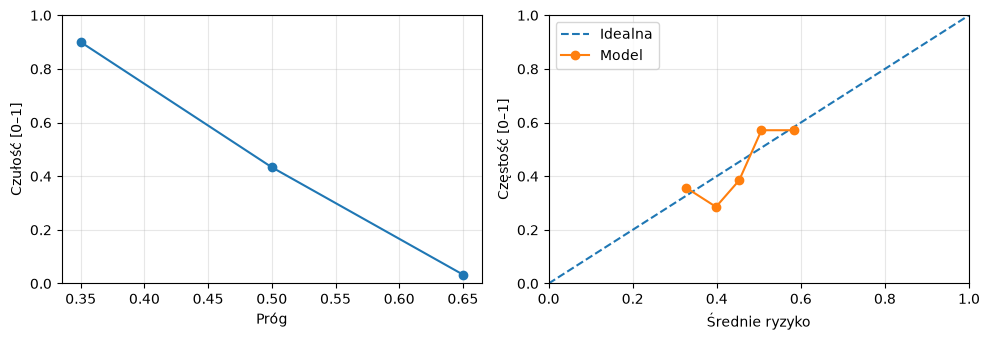

In [6]:
from sklearn.metrics import confusion_matrix
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt
progi=[.35,.50,.65];czul=[]
for prog in progi:
    tn,fp,fn,tp=confusion_matrix(y[te],p>=prog,labels=[0,1]).ravel()
    czul.append(tp/(tp+fn));print(prog,tn,fp,fn,tp)
czestosc,ryzyko=calibration_curve(y[te],p,n_bins=5,strategy="quantile")
fig,ax=plt.subplots(1,2,figsize=(10,3.5))
ax[0].plot(progi,czul,marker="o")
ax[0].set(xlabel="Próg",ylabel="Czułość [0–1]",ylim=(0,1))
ax[1].plot([0,1],[0,1],"--",label="Idealna")
ax[1].plot(ryzyko,czestosc,marker="o",label="Model")
ax[1].set(xlabel="Średnie ryzyko",ylabel="Częstość [0–1]",
          xlim=(0,1),ylim=(0,1))
ax[1].legend()
for panel in ax:panel.grid(alpha=.3)
plt.tight_layout();plt.show()
